## TESIS DE MELANY CRISTINA HUARCAYA
### Análisis Exploratorio de Datos (EDA)

Este notebook es **exclusivamente exploratorio**: entender los datos, documentar
anomalías y visualizar relaciones con el target. Toda la lógica del experimento
reproducible (partición, búsqueda de hiperparámetros, entrenamiento, métricas,
SHAP, Fairlearn) vive en `src/run_experiment.py` y `src/utils.py`, para no
duplicar código entre el notebook y el pipeline (ver README.md, sección
"Metodología").

Para ejecutar el experimento completo:
```bash
pip install -r requirements.txt
python src/run_experiment.py
```


In [1]:
%matplotlib inline
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))
import utils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## 1. Carga de datos

In [2]:
DATA_PATH = Path.cwd().parent / "data" / "raw" / "DATA.csv"
df_raw = utils.load_data(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()


Shape: (30000, 25)


,ID,MONTO_PP,SEXO,EDUCACION,ESTADO_CIVIL,EDAD,PAGO_M1,PAGO_M2,PAGO_M3,PAGO_M4,PAGO_M5,PAGO_M6,MONTO_FACTU_M1,MONTO_FACTU_M2,MONTO_FACTU_M3,MONTO_FACTU_M4,MONTO_FACTU_M5,MONTO_FACTU_M6,PAGO_EFECT_M1,PAGO_EFECT_M2,PAGO_EFECT_M3,PAGO_EFECT_M4,PAGO_EFECT_M5,PAGO_EFECT_M6,Y
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Inspección general

Antes de cualquier transformación: filas/columnas, tipos, nulos, cardinalidad,
duplicados y posibles identificadores.

In [3]:
print("Filas x Columnas:", df_raw.shape)
print("\nTipos de dato:")
print(df_raw.dtypes)


Filas x Columnas: (30000, 25)

Tipos de dato:
ID                int64
MONTO_PP          int64
SEXO              int64
EDUCACION         int64
ESTADO_CIVIL      int64
EDAD              int64
PAGO_M1           int64
PAGO_M2           int64
PAGO_M3           int64
PAGO_M4           int64
PAGO_M5           int64
PAGO_M6           int64
MONTO_FACTU_M1    int64
MONTO_FACTU_M2    int64
MONTO_FACTU_M3    int64
MONTO_FACTU_M4    int64
MONTO_FACTU_M5    int64
MONTO_FACTU_M6    int64
PAGO_EFECT_M1     int64
PAGO_EFECT_M2     int64
PAGO_EFECT_M3     int64
PAGO_EFECT_M4     int64
PAGO_EFECT_M5     int64
PAGO_EFECT_M6     int64
Y                 int64
dtype: object


In [4]:
print("Nulos por columna:")
print(df_raw.isnull().sum())
print("\nFilas duplicadas (todas las columnas):", df_raw.duplicated().sum())
print("ID únicos:", df_raw['ID'].nunique(), "de", len(df_raw), "filas -> identificador limpio, se excluye como predictor")


Nulos por columna:
ID                0
MONTO_PP          0
SEXO              0
EDUCACION         0
ESTADO_CIVIL      0
EDAD              0
PAGO_M1           0
PAGO_M2           0
PAGO_M3           0
PAGO_M4           0
PAGO_M5           0
PAGO_M6           0
MONTO_FACTU_M1    0
MONTO_FACTU_M2    0
MONTO_FACTU_M3    0
MONTO_FACTU_M4    0
MONTO_FACTU_M5    0
MONTO_FACTU_M6    0
PAGO_EFECT_M1     0
PAGO_EFECT_M2     0
PAGO_EFECT_M3     0
PAGO_EFECT_M4     0
PAGO_EFECT_M5     0
PAGO_EFECT_M6     0
Y                 0
dtype: int64

Filas duplicadas (todas las columnas): 0
ID únicos: 30000 de 30000 filas -> identificador limpio, se excluye como predictor


In [5]:
print("Cardinalidad por variable:")
for c in df_raw.columns:
    print(f"  {c:20s} {df_raw[c].nunique()}")


Cardinalidad por variable:
  ID                   30000
  MONTO_PP             81
  SEXO                 2
  EDUCACION            7
  ESTADO_CIVIL         4
  EDAD                 56
  PAGO_M1              11
  PAGO_M2              11
  PAGO_M3              11
  PAGO_M4              11
  PAGO_M5              10
  PAGO_M6              10
  MONTO_FACTU_M1       22723
  MONTO_FACTU_M2       22346
  MONTO_FACTU_M3       22026
  MONTO_FACTU_M4       21548
  MONTO_FACTU_M5       21010
  MONTO_FACTU_M6       20604
  PAGO_EFECT_M1        7943
  PAGO_EFECT_M2        7899
  PAGO_EFECT_M3        7518
  PAGO_EFECT_M4        6937
  PAGO_EFECT_M5        6897
  PAGO_EFECT_M6        6939
  Y                    2


## 3. Variable objetivo (Y)

Variable binaria: `Y=1` representa default de pago el mes siguiente.
Está **desbalanceada** (~22% positivos), lo que se tiene en cuenta en la
metodología (class_weight='balanced', métricas robustas a desbalance como
AUC/GINI/KS/F1 en vez de solo Accuracy).

Y
0    23364
1     6636
Name: count, dtype: int64
Y
0    0.7788
1    0.2212
Name: proportion, dtype: float64


/home/claude/thesis-project/src/utils.py:351: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index.astype(str), y=counts.values, palette="viridis")


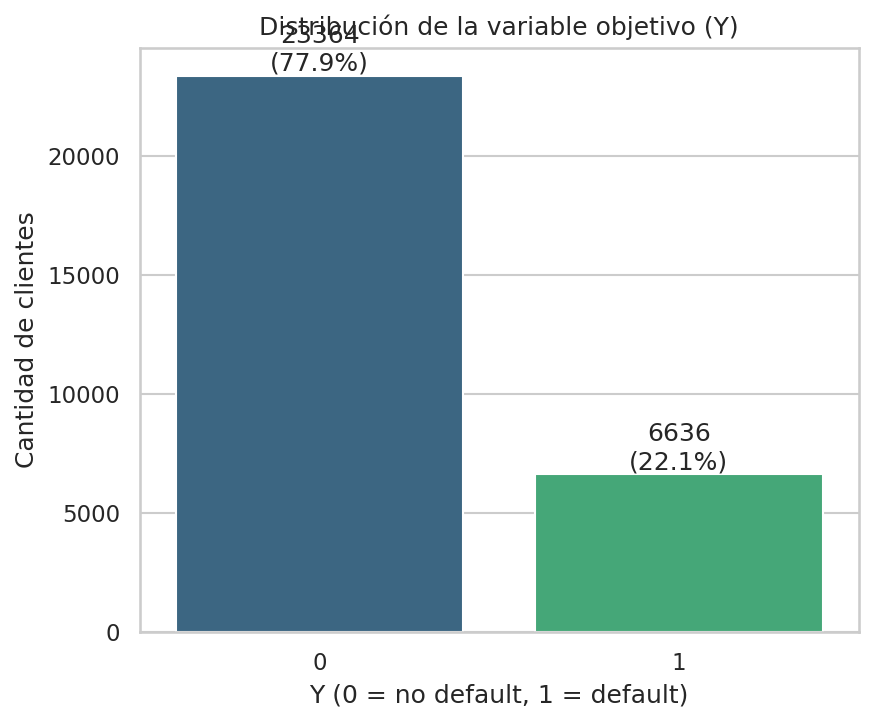

In [6]:
print(df_raw['Y'].value_counts())
print(df_raw['Y'].value_counts(normalize=True))
utils.plot_target_distribution(df_raw['Y'], Path.cwd() / "_tmp_target_dist.png")
from IPython.display import Image
Image(str(Path.cwd() / "_tmp_target_dist.png"))


## 4. Variables categóricas: anomalías documentadas

`EDUCACION` (documentado: 1-4) y `ESTADO_CIVIL` (documentado: 1-3) tienen
categorías fuera de rango (0, 5, 6). **No se eliminan filas automáticamente**:
se documentan aquí y se agrupan de forma determinística en `utils.clean_anomalous_categories`
(ver `src/utils.py`), lo cual es seguro de aplicar antes o después del split
porque no aprende ningún parámetro de los datos.

In [7]:
for col in ['SEXO', 'EDUCACION', 'ESTADO_CIVIL']:
    print(f"\n{col}:")
    print(df_raw[col].value_counts().sort_index())



SEXO:
SEXO
1    11888
2    18112
Name: count, dtype: int64

EDUCACION:
EDUCACION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

ESTADO_CIVIL:
ESTADO_CIVIL
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


## 5. Variables numéricas: estadísticos descriptivos y outliers

Los montos de facturación (`MONTO_FACTU_Mx`) presentan valores negativos, que
representan saldo a favor del cliente (créditos/pagos en exceso) — es un valor
válido para este tipo de variable, no un error de captura.

In [8]:
numeric_features, categorical_features = utils.get_feature_types(df_raw.drop(columns=['ID']))
df_raw[numeric_features].describe().transpose()


,count,mean,std,min,25%,50%,75%,max
MONTO_PP,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
EDAD,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAGO_M1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAGO_M2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAGO_M3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAGO_M4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAGO_M5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0
PAGO_M6,30000.0,-0.291100,1.149988,-2.0,-1.00,0.0,0.00,8.0
MONTO_FACTU_M1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
MONTO_FACTU_M2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0


## 6. Variables temporales / OOT

No existe ninguna columna de fecha/timestamp en el dataset. Los sufijos
`_M1..M6` representan una ventana de 6 meses **por cliente**, no una línea de
tiempo compartida entre clientes, por lo que **no es posible construir un
Out-of-Time (OOT) genuino** sin inventar un supuesto sobre fechas que el
dataset no provee. La partición usada en el experimento es Train / Validación
(Cross-Validation) / Test — ver README.md, sección "Metodología".

## 7. Riesgo de leakage

Se revisó cada variable predictora contra la definición del target:

- Todas las variables de pago/facturación (`PAGO_Mx`, `MONTO_FACTU_Mx`,
  `PAGO_EFECT_Mx`) corresponden a los 6 meses **previos** al evento que
  predice `Y` — no hay leakage temporal directo.
- `ID` se excluye por ser un identificador sin poder predictivo real.
- No hay variables derivadas del target ni columnas que codifiquen `Y`
  directa o indirectamente.
- Sí existe **multicolinealidad alta** entre variables consecutivas del mismo
  bloque (ver matriz de correlación abajo), tratada con ingeniería de
  variables agregadas (MAX/MIN/STD) y selección de variables por SHAP dentro
  del pipeline (`src/run_experiment.py`), nunca antes del split.

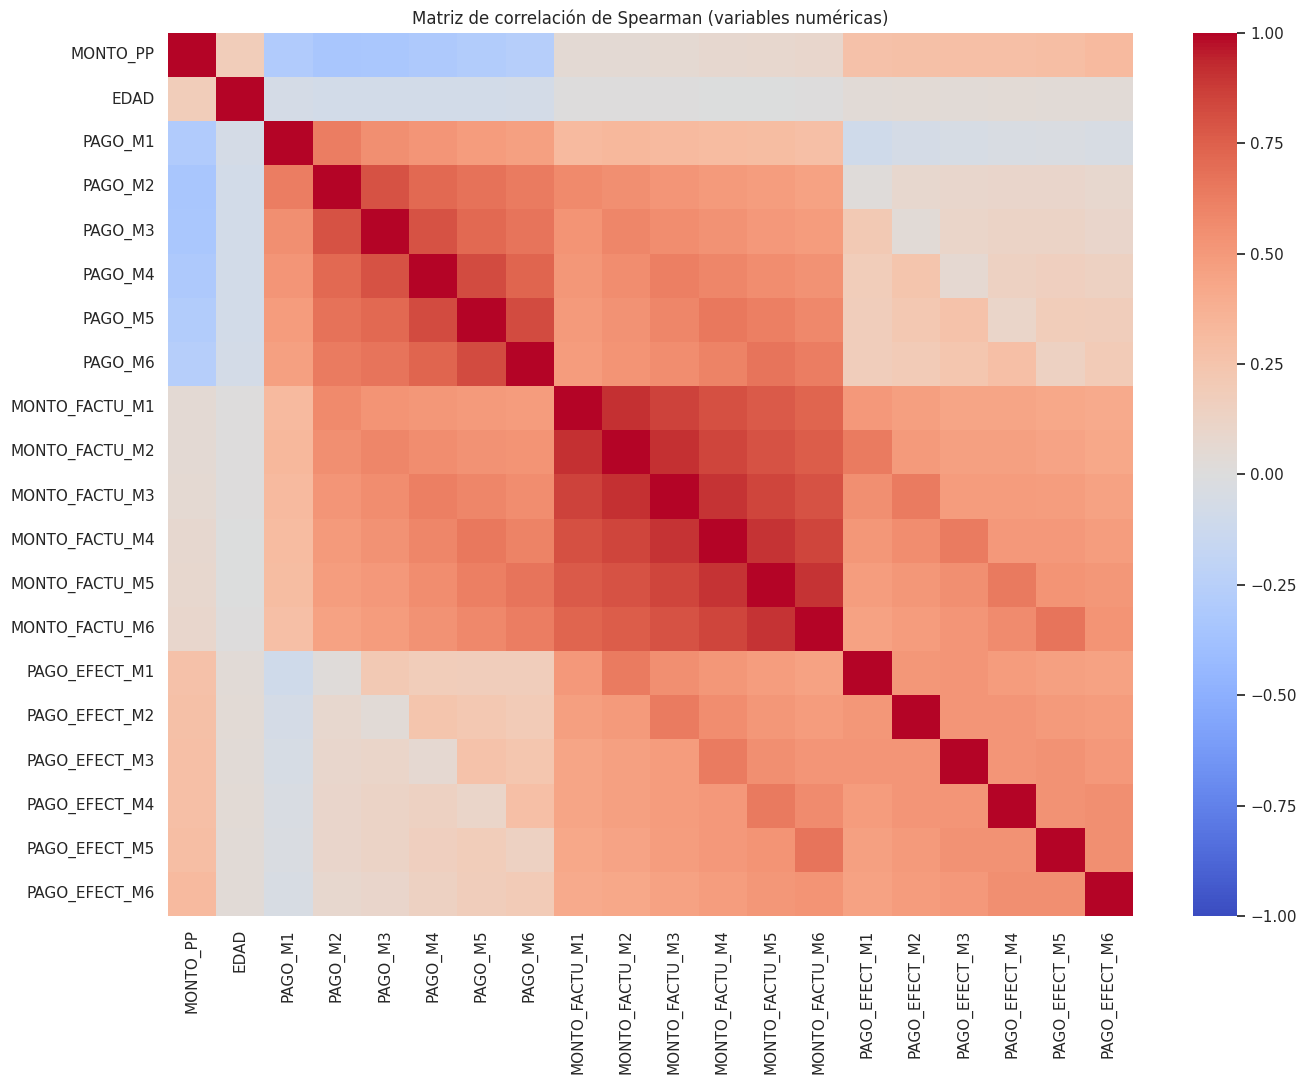

In [9]:
corr = df_raw[numeric_features].corr(method="spearman")
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlación de Spearman (variables numéricas)")
plt.tight_layout()
plt.show()


## 8. Bad rate por decil / categoría

Relación entre cada variable y la tasa de incumplimiento (`Y`), para
identificar qué variables separan mejor a los clientes buenos de los malos.

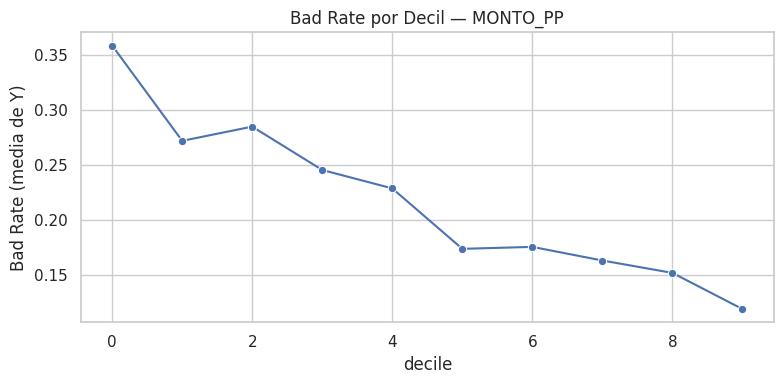

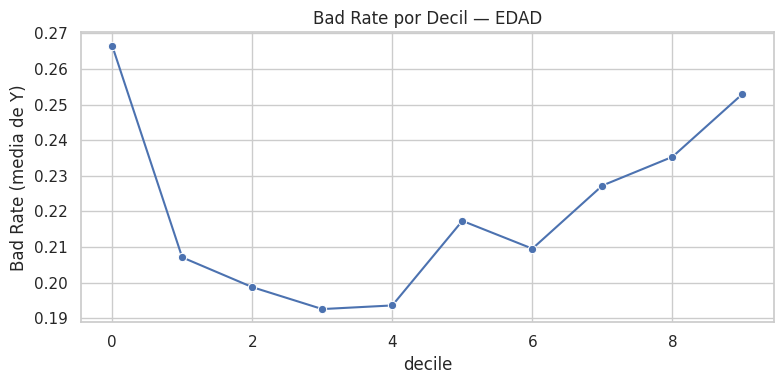

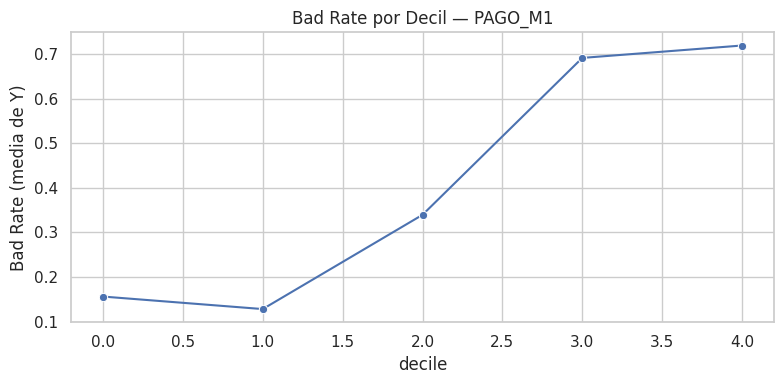

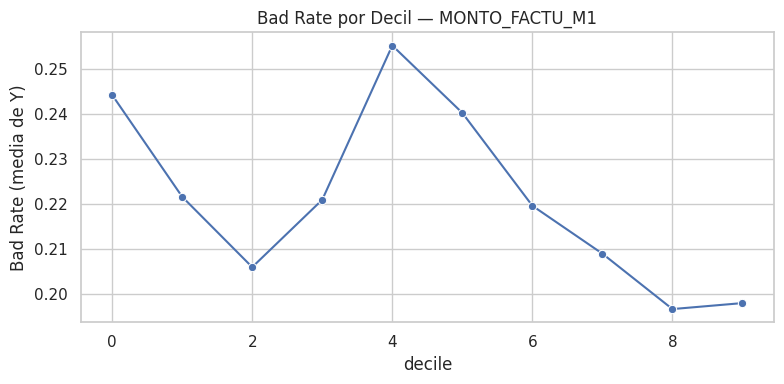

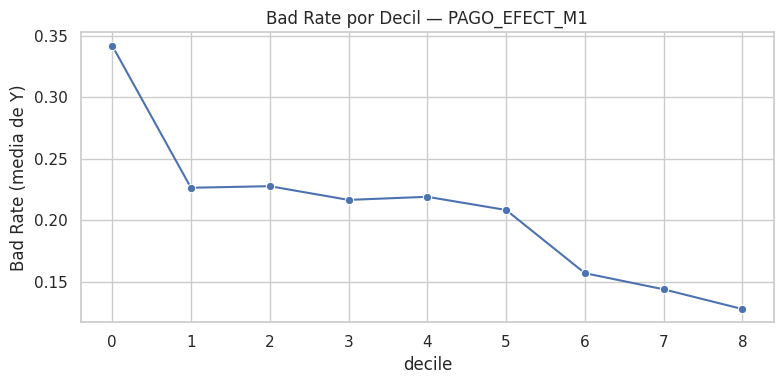

In [10]:
def plot_bad_rate_by_decile(df, feature, target='Y'):
    d = df[[feature, target]].copy()
    d['decile'] = pd.qcut(d[feature], 10, labels=False, duplicates='drop')
    rates = d.groupby('decile')[target].mean().reset_index()
    plt.figure(figsize=(8, 4))
    sns.lineplot(x='decile', y=target, data=rates, marker='o')
    plt.title(f'Bad Rate por Decil — {feature}')
    plt.ylabel('Bad Rate (media de Y)')
    plt.tight_layout()
    plt.show()

for feature in ['MONTO_PP', 'EDAD', 'PAGO_M1', 'MONTO_FACTU_M1', 'PAGO_EFECT_M1']:
    plot_bad_rate_by_decile(df_raw, feature)


/tmp/ipykernel_821/1018670009.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature, y=target, data=rates, palette='viridis')


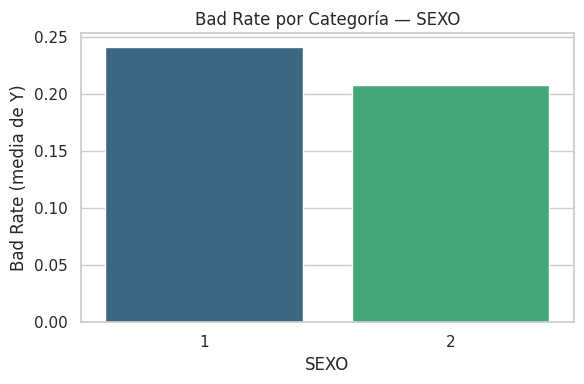

/tmp/ipykernel_821/1018670009.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature, y=target, data=rates, palette='viridis')


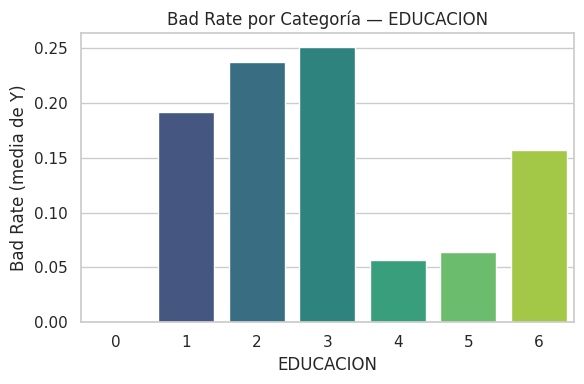

/tmp/ipykernel_821/1018670009.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature, y=target, data=rates, palette='viridis')


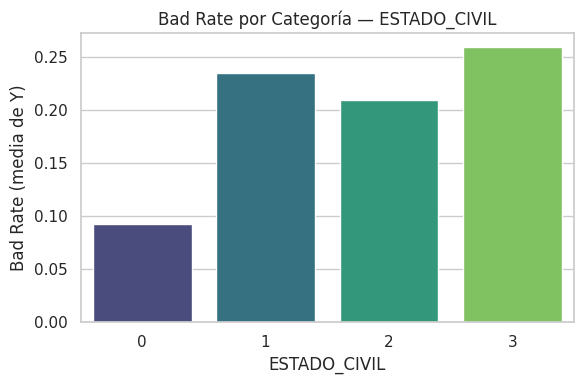

In [11]:
def plot_bad_rate_by_category(df, feature, target='Y'):
    rates = df.groupby(feature)[target].mean().reset_index()
    plt.figure(figsize=(6, 4))
    sns.barplot(x=feature, y=target, data=rates, palette='viridis')
    plt.title(f'Bad Rate por Categoría — {feature}')
    plt.ylabel('Bad Rate (media de Y)')
    plt.tight_layout()
    plt.show()

for feature in ['SEXO', 'EDUCACION', 'ESTADO_CIVIL']:
    plot_bad_rate_by_category(df_raw, feature)


## 9. Variable sensible para el análisis de fairness

Se seleccionó **SEXO** como variable sensible para el análisis de Fairlearn
(ver `src/run_experiment.py` y `results/fairness_results.json`): es binaria,
no tiene categorías anómalas, y es la variable demográfica estándar para este
tipo de análisis en modelos de riesgo crediticio. `EDUCACION` y
`ESTADO_CIVIL` se descartaron para este fin por arrastrar categorías fuera de
rango que complicarían la interpretación de los grupos.

## 10. Ingeniería de variables (preview)

`utils.add_engineered_features` agrega MAX/MIN/STD por fila sobre los tres
bloques temporales. Al ser operaciones fila a fila (no aprenden ningún
parámetro de la muestra), son seguras de calcular en cualquier momento del
pipeline sin generar leakage.

In [12]:
df_fe = utils.add_engineered_features(utils.clean_anomalous_categories(df_raw))
df_fe[['PAGO_M_MAX', 'PAGO_M_MIN', 'PAGO_M_STD',
       'MONTO_FACTU_M_MAX', 'MONTO_FACTU_M_MIN', 'MONTO_FACTU_M_STD',
       'PAGO_EFECT_M_MAX', 'PAGO_EFECT_M_MIN', 'PAGO_EFECT_M_STD']].describe().transpose()


,count,mean,std,min,25%,50%,75%,max
PAGO_M_MAX,30000.0,0.253233,1.354560,-2.0,0.000000,0.000000,2.000000,8.000000e+00
PAGO_M_MIN,30000.0,-0.570333,0.977353,-2.0,-1.000000,0.000000,0.000000,4.000000e+00
PAGO_M_STD,30000.0,0.388276,0.504788,0.0,0.000000,0.000000,0.894427,3.271085e+00
MONTO_FACTU_M_MAX,30000.0,60572.436867,78404.814025,-6029.0,10060.000000,31208.500000,79599.000000,1.664089e+06
MONTO_FACTU_M_MIN,30000.0,31722.210800,54719.577753,-339603.0,0.000000,8664.500000,39180.500000,5.517020e+05
MONTO_FACTU_M_STD,30000.0,12077.787549,20302.149149,0.0,1549.935213,4579.662158,14352.259579,6.477881e+05
PAGO_EFECT_M_MAX,30000.0,15848.230133,37933.561204,0.0,2198.000000,5000.000000,12100.000000,1.684259e+06
PAGO_EFECT_M_MIN,30000.0,1243.651433,2472.828190,0.0,0.000000,17.000000,1500.000000,6.375800e+04
PAGO_EFECT_M_STD,30000.0,5804.918519,15006.438973,0.0,615.353672,1413.694125,4126.957632,6.500983e+05


## 11. Siguientes pasos

El pipeline experimental completo (partición, selección de variables SHAP,
búsqueda de hiperparámetros, baseline vs modelos propuestos, 10 corridas de
estabilidad, Fairlearn, SHAP, figuras y guardado de modelos) se ejecuta con:

```bash
python src/run_experiment.py
```

Los resultados quedan en `results/` (métricas, figuras, JSON) y los modelos
entrenados en `models/`. Ver `README.md` para el detalle metodológico
completo.

In [13]:
import os
tmp = Path.cwd() / "_tmp_target_dist.png"
if tmp.exists():
    os.remove(tmp)
